<a href="https://colab.research.google.com/github/Goutham-kc/AIML/blob/main/DecisionTree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (27528, 9)

First 5 rows:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  

Training data: (22022, 13)
Testing data: (5506, 13)

Accuracy: 0.9742099527787867

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.97      1.00      0.99      5034
    Diabetes       1.00     

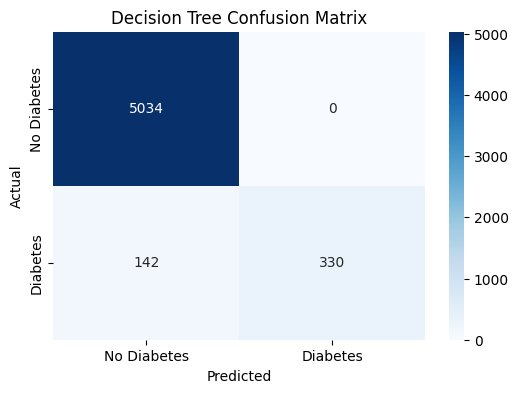


Feature Importance:
HbA1c_level                    0.658713
blood_glucose_level            0.326255
age                            0.012431
bmi                            0.001606
hypertension                   0.000994
heart_disease                  0.000000
gender_Male                    0.000000
gender_Other                   0.000000
smoking_history_current        0.000000
smoking_history_ever           0.000000
smoking_history_former         0.000000
smoking_history_never          0.000000
smoking_history_not current    0.000000
dtype: float64


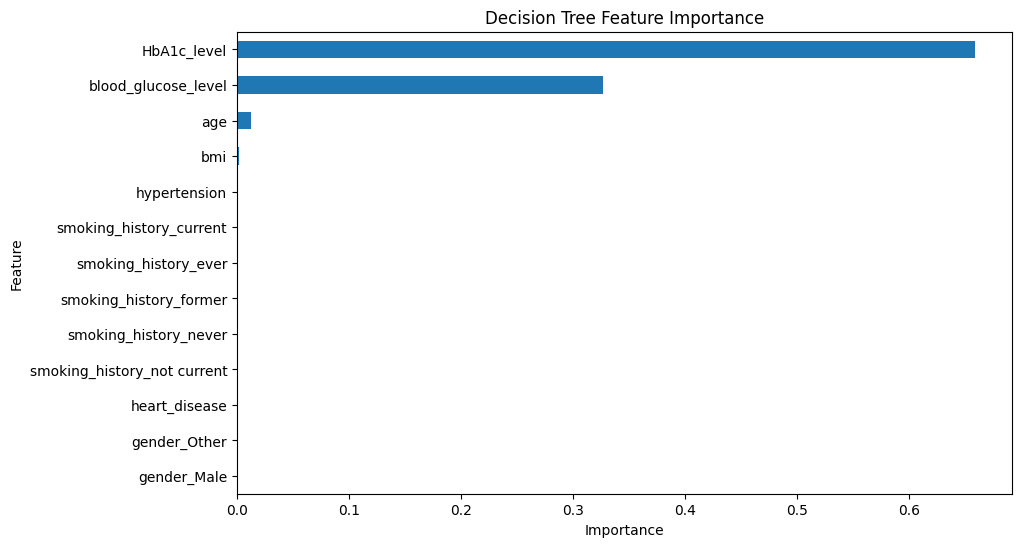

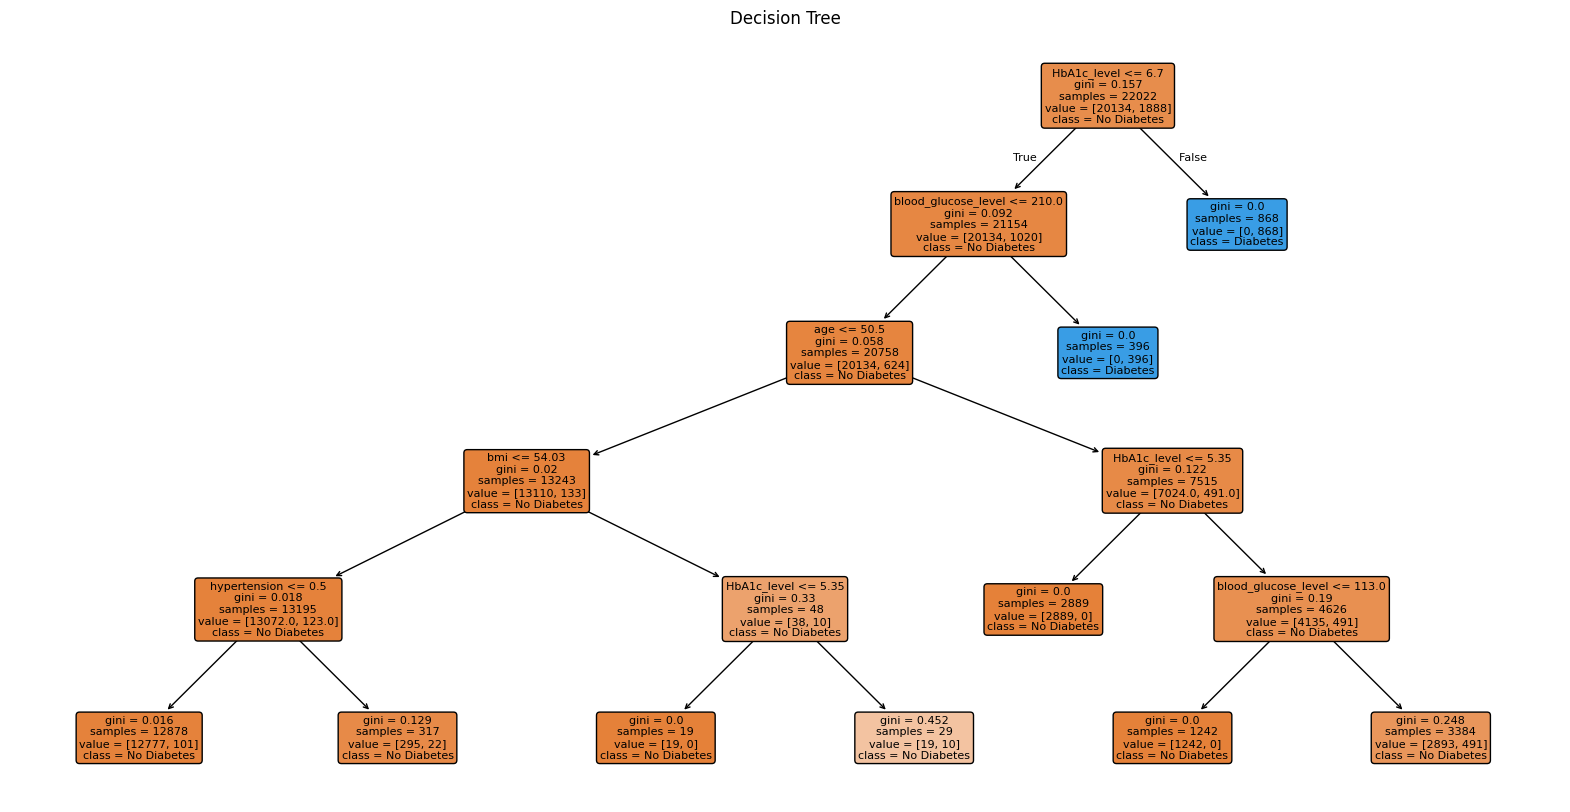

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load dataset
df = pd.read_csv("diabetes_prediction_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# 2. Separate features and target
X = df.drop("diabetes", axis=1)
y = df["diabetes"]

# 3. Convert categorical columns to numerical columns
X = pd.get_dummies(X, drop_first=True)

# 4. Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)

# 5. Create Decision Tree Classifier
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

# 6. Train the model
model.fit(X_train, y_train)

# 7. Make predictions
y_pred = model.predict(X_test)

# 8. Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)

# 9. Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes", "Diabetes"]
))

# 10. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# 11. Plot Confusion Matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.show()

# 12. Feature Importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nFeature Importance:")
print(importance)

# 13. Plot Feature Importance
plt.figure(figsize=(10, 6))

importance.sort_values().plot(kind="barh")

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

# 14. Visualize Decision Tree
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree")
plt.show()